In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import statsmodels.api as sm
import math

from scipy.stats import chi2
from scipy.stats import chi2_contingency
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

from sklearn.model_selection import train_test_split


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yuanchunhong/university-football-injury-prediction-dataset")

print("Path to dataset files:", path)                   

c:\Users\USER\115-1_DAM\HW4\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\USER\.cache\kagglehub\datasets\yuanchunhong\university-football-injury-prediction-dataset\versions\2


In [3]:
from pathlib import Path

csv_files = sorted(Path(path).rglob("*.csv"))

# Data Reading

In [4]:
df = pd.read_csv(csv_files[0])

print("資料形狀：", df.shape)
display(df.head(10))

資料形狀： (800, 19)


,Age,Height_cm,Weight_kg,Position,Training_Hours_Per_Week,Matches_Played_Past_Season,Previous_Injury_Count,Knee_Strength_Score,Hamstring_Flexibility,Reaction_Time_ms,Balance_Test_Score,Sprint_Speed_10m_s,Agility_Score,Sleep_Hours_Per_Night,Stress_Level_Score,Nutrition_Quality_Score,Warmup_Routine_Adherence,Injury_Next_Season,BMI
0,22,173,64,Midfielder,11.575308,36,1,77.460279,79.115738,284.487853,91.212476,5.874630,77.599705,8.238293,46.616415,81.472206,1,0,21.383942
1,18,170,67,Midfielder,12.275869,37,2,72.634442,82.541688,250.579249,87.294078,5.796269,94.418987,8.983737,49.368037,81.056677,1,0,23.183391
2,22,186,75,Forward,12.254896,12,2,77.064490,75.943631,269.119918,83.440688,5.731209,70.179176,7.229193,43.132808,64.877457,0,1,21.678807
3,20,172,62,Defender,9.006678,11,1,82.810232,73.878324,226.376412,87.591894,6.220212,83.473824,7.681029,51.528529,89.824744,1,0,20.957274
4,18,172,94,Midfielder,12.683668,10,2,76.772859,76.653043,229.021042,83.125161,5.385958,87.037256,6.728091,52.379718,71.569197,0,1,31.773932
5,23,189,89,Goalkeeper,10.262987,31,2,78.450720,80.927984,265.801623,81.106339,6.354870,86.418954,8.538027,39.929697,74.982476,1,0,24.915316
6,22,189,71,Midfielder,8.069288,5,4,63.045009,75.032030,269.099907,76.787369,6.458297,65.179995,7.339327,75.039112,65.790192,0,1,19.876263
7,23,184,75,Goalkeeper,6.407939,26,0,77.566677,76.947213,226.966431,93.317382,6.161460,79.260417,8.072895,25.783371,89.782578,0,0,22.152647
8,22,174,71,Midfielder,10.554931,23,0,78.877905,89.584501,240.745054,80.898575,6.199281,77.152290,7.661190,52.581600,78.587201,1,0,23.450918
9,23,185,76,Midfielder,11.899732,22,0,83.194761,82.244364,259.628161,89.077577,6.206694,90.396480,6.035505,55.049722,83.947949,1,0,22.205990


In [5]:
print("=== 欄位名稱 ===")
print(df.columns.tolist())

print("\n=== 資料型態 ===")
df.info()

print("\n=== 缺失值 ===")
display(df.isna().sum().to_frame("Missing_Count"))

=== 欄位名稱 ===
['Age', 'Height_cm', 'Weight_kg', 'Position', 'Training_Hours_Per_Week', 'Matches_Played_Past_Season', 'Previous_Injury_Count', 'Knee_Strength_Score', 'Hamstring_Flexibility', 'Reaction_Time_ms', 'Balance_Test_Score', 'Sprint_Speed_10m_s', 'Agility_Score', 'Sleep_Hours_Per_Night', 'Stress_Level_Score', 'Nutrition_Quality_Score', 'Warmup_Routine_Adherence', 'Injury_Next_Season', 'BMI']

=== 資料型態 ===
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         800 non-null    int64  
 1   Height_cm                   800 non-null    int64  
 2   Weight_kg                   800 non-null    int64  
 3   Position                    800 non-null    str    
 4   Training_Hours_Per_Week     800 non-null    float64
 5   Matches_Played_Past_Season  800 non-null    int64  
 6   Previous_Injury_Count       80

,Missing_Count
Age,0
Height_cm,0
Weight_kg,0
Position,0
Training_Hours_Per_Week,0
Matches_Played_Past_Season,0
Previous_Injury_Count,0
Knee_Strength_Score,0
Hamstring_Flexibility,0
Reaction_Time_ms,0


In [6]:
print("=== Injury Next Season ===")

display(
    pd.DataFrame({
        "Count": df["Injury_Next_Season"].value_counts().sort_index(),
        "Percentage": (
            df["Injury_Next_Season"]
            .value_counts(normalize=True)
            .sort_index() * 100
        ).round(2)
    })
)

=== Injury Next Season ===


,Count,Percentage
Injury_Next_Season,,
0,400,50.0
1,400,50.0


In [7]:
for col in ["Position", "Warmup_Routine_Adherence"]:
    print(f"\n=== {col} ===")
    display(df[col].value_counts(dropna=False))


=== Position ===


Position
Midfielder    213
Defender      204
Forward       197
Goalkeeper    186
Name: count, dtype: int64


=== Warmup_Routine_Adherence ===


Warmup_Routine_Adherence
1    478
0    322
Name: count, dtype: int64

In [8]:
# 檢查完全重複的資料
print("完全重複列數：", df.duplicated().sum())

# 不考慮 Y，檢查相同 X 是否重複
X_columns = df.columns.drop("Injury_Next_Season")

print(
    "相同特徵組合的重複列數：",
    df.duplicated(subset=X_columns).sum()
)

# 檢查類別和數值範圍
display(df.describe(include="all").T)

完全重複列數： 0
相同特徵組合的重複列數： 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,800.0,NaN,NaN,NaN,21.135,1.991037,18.0,19.0,21.0,23.0,24.0
Height_cm,800.0,NaN,NaN,NaN,177.4075,7.148974,154.0,173.0,177.0,182.0,200.0
Weight_kg,800.0,NaN,NaN,NaN,73.235,9.929276,45.0,66.0,73.0,80.0,105.0
Position,800,4,Midfielder,213,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Training_Hours_Per_Week,800.0,NaN,NaN,NaN,9.95115,2.610395,5.0,8.127151,9.89571,11.53514,18.866608
Matches_Played_Past_Season,800.0,NaN,NaN,NaN,22.3325,10.311516,5.0,13.0,22.0,32.0,39.0
Previous_Injury_Count,800.0,NaN,NaN,NaN,1.53625,1.292584,0.0,1.0,1.0,2.0,8.0
Knee_Strength_Score,800.0,NaN,NaN,NaN,74.933249,6.672704,52.391351,70.432656,74.997933,79.632391,93.900051
Hamstring_Flexibility,800.0,NaN,NaN,NaN,79.154123,6.782332,58.180381,74.495959,79.187909,83.813179,100.0
Reaction_Time_ms,800.0,NaN,NaN,NaN,249.423244,22.532387,180.0,234.089585,249.127328,265.105082,306.730851


## continuous varable distribution

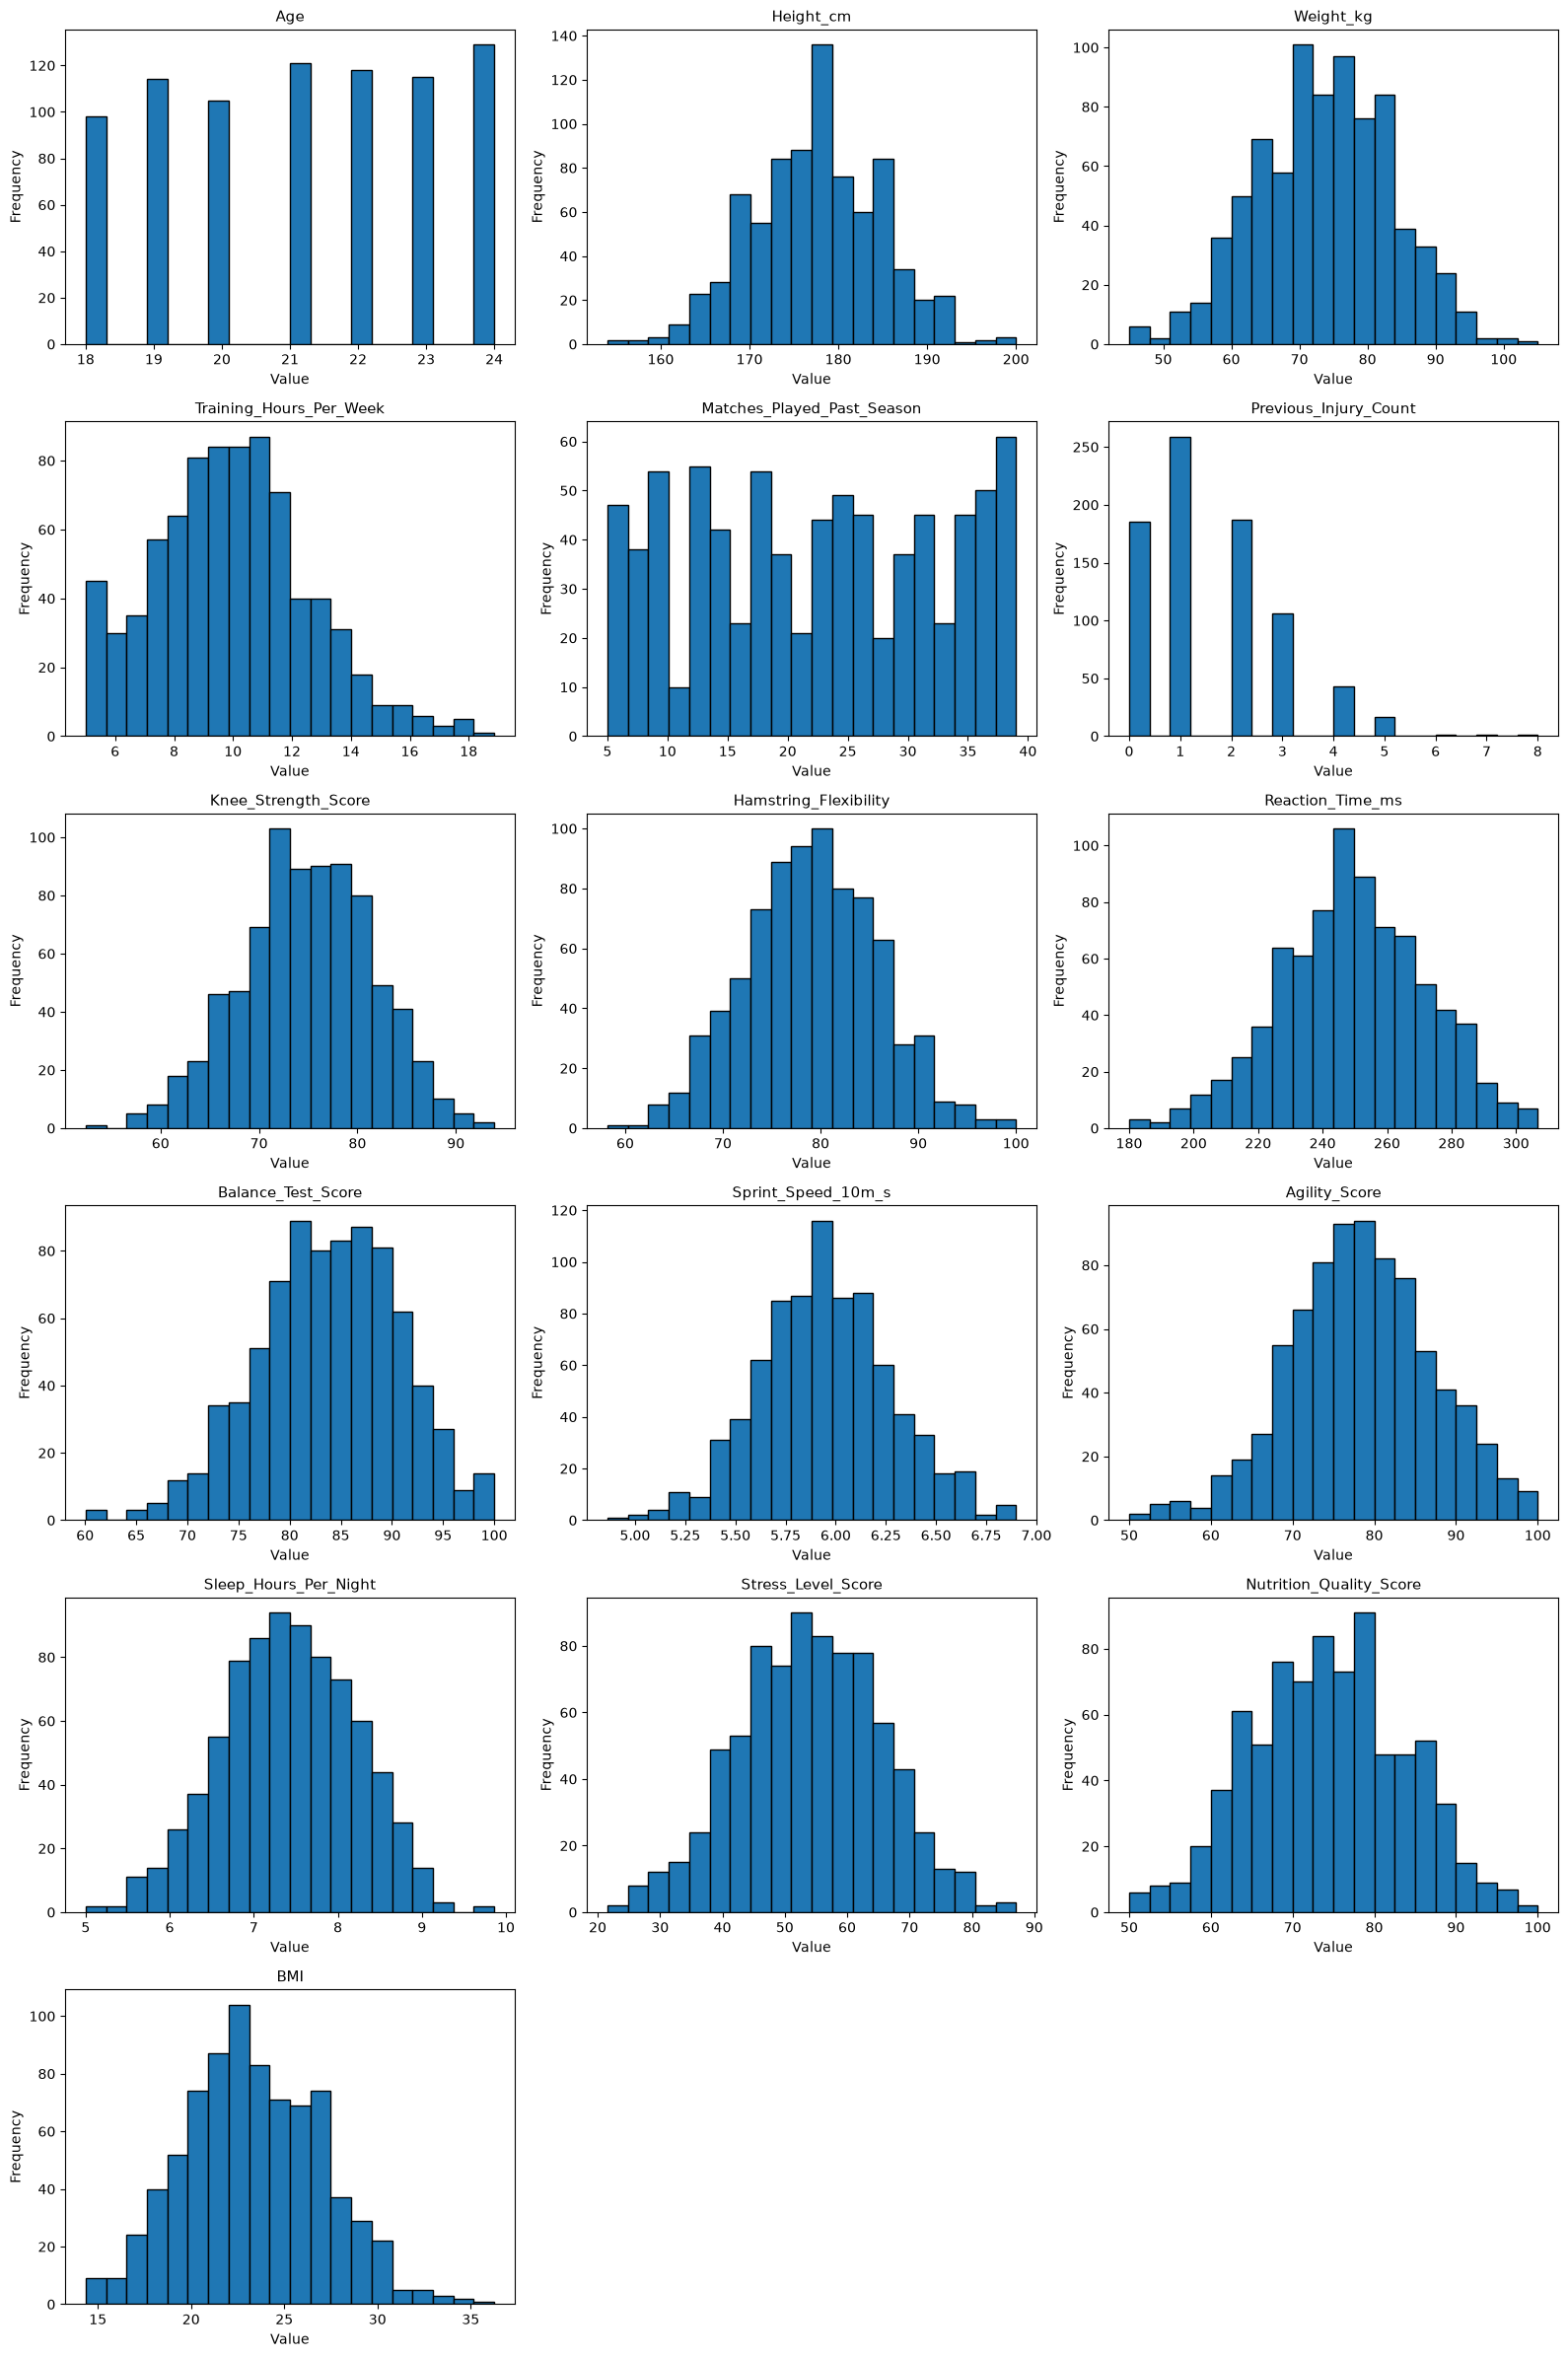

In [9]:
# 選擇數值型自變數
numeric_cols = df.select_dtypes(include="number").columns.tolist()

# 排除二元類別型變數與應變數
numeric_cols = [
    col for col in numeric_cols
    if col not in [
        "Warmup_Routine_Adherence",
        "Injury_Next_Season"
    ]
]

# 畫出所有數值型變數的直方圖
n_cols = 3
n_rows = math.ceil(len(numeric_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(16, 4 * n_rows)
)

axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].hist(
        df[col],
        bins=20,
        edgecolor="black"
    )

    axes[i].set_title(col, fontsize=11)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")

# 移除空白子圖
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [10]:
outlier_summary = []

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (df[col] < lower) | (df[col] > upper)

    outlier_summary.append({
        "Variable": col,
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2),
        "Outlier Count": int(outliers.sum()),
        "Outlier Percentage": round(outliers.mean() * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)

display(
    outlier_df.sort_values(
        "Outlier Percentage",
        ascending=False
    )
)

,Variable,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
5,Previous_Injury_Count,-0.50,3.50,63,7.88
1,Height_cm,159.50,195.50,11,1.38
3,Training_Hours_Per_Week,3.02,16.65,10,1.25
10,Sprint_Speed_10m_s,5.09,6.80,9,1.12
11,Agility_Score,55.55,101.22,7,0.88
7,Hamstring_Flexibility,60.52,97.79,4,0.50
8,Reaction_Time_ms,187.57,311.63,3,0.38
9,Balance_Test_Score,64.30,103.63,3,0.38
15,BMI,12.93,33.88,3,0.38
12,Sleep_Hours_Per_Night,5.14,9.70,2,0.25


# Modeling

## Split Data
一般隨機抽樣無法保證各組的受傷比例相同，尤其 Validation 和 Testing 的樣本比較少，比例可能產生偏差。分層抽樣可以降低這種抽樣造成的類別比例波動，讓三種 Decision Tree 使用相同且較具代表性的資料進行比較。

In [11]:
# 原始資料
data = df.copy()

# 使用分層抽樣
# 第一次切分：85% 開發資料、15% Testing
train_val, test = train_test_split(
    data,
    test_size=0.15,
    random_state=42,                    # 確保每次切分結果一致
    stratify=data["Injury_Next_Season"] # 根據y的比例分層
)

# 第二次切分：開發資料中取出 120 筆 Validation
train, val = train_test_split(
    train_val,
    test_size=120,
    random_state=42,
    stratify=train_val["Injury_Next_Season"]
)

# 整理各資料集資訊
summary = []

for name, subset in [
    ("Training", train),
    ("Validation", val),
    ("Testing", test)
]:
    summary.append({
        "Dataset": name,
        "Samples": len(subset),
        "Not Injured (0)": (
            subset["Injury_Next_Season"] == 0
        ).sum(),
        "Injured (1)": (
            subset["Injury_Next_Season"] == 1
        ).sum()
    })

display(pd.DataFrame(summary))

,Dataset,Samples,Not Injured (0),Injured (1)
0,Training,560,280,280
1,Validation,120,60,60
2,Testing,120,60,60


In [12]:
assert set(train.index).isdisjoint(val.index)
assert set(train.index).isdisjoint(test.index)
assert set(val.index).isdisjoint(test.index)

print("三組資料切分成功，沒有重疊樣本！")

三組資料切分成功，沒有重疊樣本！


## 建立 x,y encode

In [13]:
target = "Injury_Next_Season"       # 0 未受傷／1 受傷

X_train = train.drop(columns=[target]).copy()
y_train = train[target].copy()

X_val = val.drop(columns=[target]).copy()
y_val = val[target].copy()

X_test = test.drop(columns=[target]).copy()
y_test = test[target].copy()

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (560, 18) (560,)
Validation: (120, 18) (120,)
Testing: (120, 18) (120,)


In [14]:
# 處理類別型變數 Position

# One-Hot Encoding
# decision tree 不需要為了避免多重共線性而刪除其中一個欄位，因此不需要 drop_first=True
X_train_encoded = pd.get_dummies(
    X_train,
    columns=["Position"],
    dtype=int
)

X_val_encoded = pd.get_dummies(
    X_val,
    columns=["Position"],
    dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test,
    columns=["Position"],
    dtype=int
)

# 保證 Validation 和 Testing 的欄位與 Training 完全相同
X_val_encoded = X_val_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

print("Training:", X_train_encoded.shape)
print("Validation:", X_val_encoded.shape)
print("Testing:", X_test_encoded.shape)

display(X_train_encoded.head())

Training: (560, 21)
Validation: (120, 21)
Testing: (120, 21)


,Age,Height_cm,Weight_kg,Training_Hours_Per_Week,Matches_Played_Past_Season,Previous_Injury_Count,Knee_Strength_Score,Hamstring_Flexibility,Reaction_Time_ms,Balance_Test_Score,...,Agility_Score,Sleep_Hours_Per_Night,Stress_Level_Score,Nutrition_Quality_Score,Warmup_Routine_Adherence,BMI,Position_Defender,Position_Forward,Position_Goalkeeper,Position_Midfielder
478,18,175,75,7.497979,34,3,64.934012,74.898749,247.530996,95.717049,...,85.065727,6.259148,77.763502,57.795154,0,24.489796,0,0,0,1
726,19,173,65,7.147281,8,2,57.626080,86.323342,204.131724,85.520794,...,85.717722,6.672772,50.474837,73.617801,1,21.718066,1,0,0,0
73,24,167,68,15.193021,20,1,75.401178,82.061597,290.386030,80.916712,...,96.212492,7.658514,34.327127,66.883640,1,24.382373,0,0,0,1
410,24,179,78,10.502636,9,0,73.947297,79.999711,226.376776,87.999697,...,67.925695,7.538096,27.530865,79.027759,0,24.343809,0,0,0,1
399,22,187,63,13.114171,33,2,85.512124,75.076208,201.814442,95.233664,...,91.725885,7.589114,29.651520,77.006415,1,18.015957,0,1,0,0


## Growing Trees

In [15]:
# 初始設定
MIN_SAMPLES_SPLIT = 2
MIN_SAMPLES_LEAF = 1
MAX_DEPTH = None

# Chi-square 初始統計量
CHI2_ALPHA = 0.1

# 檢查資料
print("Training:", X_train_encoded.shape)
print("Validation:", X_val_encoded.shape)
print("Testing:", X_test_encoded.shape)

print("\nTarget distribution:")
print(y_train.value_counts().sort_index())

Training: (560, 21)
Validation: (120, 21)
Testing: (120, 21)

Target distribution:
Injury_Next_Season
0    280
1    280
Name: count, dtype: int64


### chi-square

對於每一個候選切割點：
1. 把資料分成左、右兩組。
2. 建立 \(2\times2\) 的 Observed Frequency Table。
3. 計算獨立假設下的 Expected Frequency。
4. 計算 Chi-square Statistic。
5. 比較候選切割點，選擇統計量最大的有效分裂。

In [ ]:
# 找root node

def best_chi2_split(X, y, min_samples_leaf=1):

    best = None

    # 逐一檢查所有特徵與候選切割點
    for feature in X.columns:

        values = X[feature].to_numpy()
        labels = y.to_numpy()

        # 相鄰不同數值的中點，作為候選切割點
        unique_values = np.sort(np.unique(values))

        if len(unique_values) < 2:
            continue

        thresholds = (
            unique_values[:-1] + unique_values[1:]
        ) / 2

        for threshold in thresholds:

            left = values <= threshold
            right = ~left

            if min(left.sum(), right.sum()) < min_samples_leaf:
                continue

            # 建立列聯表並計算 Chi-square
            observed = np.array([
                [
                    np.sum(left & (labels == 0)),
                    np.sum(left & (labels == 1))
                ],
                [
                    np.sum(right & (labels == 0)),
                    np.sum(right & (labels == 1))
                ]
            ])

            # 若節點內只有一種 Y，無需繼續分裂
            if np.any(observed.sum(axis=0) == 0):
                continue

            chi2, p, dof, expected = chi2_contingency(
                observed,
                correction=False
            )

            # 保留 Chi-square 最大的切割點
            if best is None or chi2 > best["chi2"]:
                best = {
                    "feature": feature,
                    "threshold": threshold,
                    "chi2": chi2,
                    "p_value": p,
                    "observed": observed,
                    "expected": expected,
                    "left_samples": int(left.sum()),
                    "right_samples": int(right.sum())
                }

    return best

In [17]:
root_split = best_chi2_split(
    X_train_encoded,
    y_train,
    min_samples_leaf=MIN_SAMPLES_LEAF
)

print("Best Feature:", root_split["feature"])
print("Best Threshold:", root_split["threshold"])
print("Chi-square:", root_split["chi2"])
print("Raw p-value:", root_split["p_value"])
print("Left Samples:", root_split["left_samples"])
print("Right Samples:", root_split["right_samples"])

print("\nObserved Frequency:")
display(pd.DataFrame(
    root_split["observed"],
    columns=["Not Injured", "Injured"],
    index=["Left Node", "Right Node"]
))

print("\nExpected Frequency:")
display(pd.DataFrame(
    root_split["expected"],
    columns=["Not Injured", "Injured"],
    index=["Left Node", "Right Node"]
))

Best Feature: Stress_Level_Score
Best Threshold: 54.091613717884755
Chi-square: 148.11428571428573
Raw p-value: 4.478667888562167e-34
Left Samples: 280
Right Samples: 280

Observed Frequency:


,Not Injured,Injured
Left Node,212,68
Right Node,68,212



Expected Frequency:


,Not Injured,Injured
Left Node,140.0,140.0
Right Node,140.0,140.0


In [ ]:
# 建立完整樹
# 按照每個node尋找最佳分裂，並記錄其樣本數、Chi-square、p-value、深度與分類結果。

class ChiSquareTree:
    def __init__(
        self,
        alpha=0.10,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        min_expected=5
    ):
        self.alpha = alpha
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_expected = min_expected

    def _best_split(self, X, y):
        best = None
        n = len(y)
        classes = np.bincount(y, minlength=2)

        if np.any(classes == 0):
            return None

        for j, feature in enumerate(self.feature_names_):
            order = np.argsort(X[:, j], kind="mergesort")
            xs = X[order, j]
            ys = y[order]

            # 只有相鄰數值不同的位置才能切割
            positions = np.flatnonzero(xs[:-1] != xs[1:]) + 1

            positions = positions[
                (positions >= self.min_samples_leaf) &
                (n - positions >= self.min_samples_leaf)
            ]

            if len(positions) == 0:
                continue

            cumulative_injured = np.cumsum(ys)

            left_n = positions
            right_n = n - positions

            left_1 = cumulative_injured[positions - 1]
            left_0 = left_n - left_1
            right_1 = classes[1] - left_1
            right_0 = classes[0] - left_0

            observed = np.stack(
                [left_0, left_1, right_0, right_1],
                axis=1
            ).astype(float)

            row_totals = np.stack(
                [left_n, right_n], axis=1
            )
            expected = (
                row_totals[:, :, None] *
                classes[None, None, :] / n
            ).reshape(-1, 4)

            # 期望次數至少 5，才使用卡方近似
            valid = np.all(
                expected >= self.min_expected, axis=1
            )

            if not np.any(valid):
                continue

            chi2_values = np.sum(
                (observed - expected) ** 2 / expected,
                axis=1
            )

            chi2_values[~valid] = -np.inf
            idx = int(np.argmax(chi2_values))

            if not np.isfinite(chi2_values[idx]):
                continue

            score = float(chi2_values[idx])

            if best is None or score > best["chi2"]:
                pos = int(positions[idx])
                threshold = (
                    float(xs[pos - 1]) +
                    float(xs[pos])
                ) / 2

                best = {
                    "feature": feature,
                    "feature_idx": j,
                    "threshold": threshold,
                    "chi2": score,
                    "p_value": float(chi2.sf(score, df=1)),
                    "observed": observed[idx].reshape(2, 2),
                    "expected": expected[idx].reshape(2, 2)
                }

        return best

    def _grow(self, X, y, depth):
        counts = np.bincount(y, minlength=2)

        node = {
            "depth": depth,
            "n_samples": len(y),
            "counts": counts,
            "prediction": int(np.argmax(counts)),
            "feature": None,
            "left": None,
            "right": None
        }

        # 停止條件 1：節點已純淨
        if np.count_nonzero(counts) == 1:
            return node

        # 停止條件 2：最大深度
        if self.max_depth is not None and depth >= self.max_depth:
            return node

        # 停止條件 3：樣本數不足
        if len(y) < self.min_samples_split:
            return node

        split = self._best_split(X, y)

        # 停止條件 4：找不到有效分裂
        if split is None:
            return node

        # 停止條件 5：未通過 alpha 門檻
        if split["p_value"] >= self.alpha:
            return node

        feature_idx = split["feature_idx"]
        threshold = split["threshold"]
        left_mask = X[:, feature_idx] <= threshold

        node.update(split)
        node["left"] = self._grow(
            X[left_mask], y[left_mask], depth + 1
        )
        node["right"] = self._grow(
            X[~left_mask], y[~left_mask], depth + 1
        )

        return node

    def fit(self, X, y):
        self.feature_names_ = list(X.columns)
        X_array = X.to_numpy(dtype=float)
        y_array = np.asarray(y, dtype=int)

        if not np.isin(y_array, [0, 1]).all():
            raise ValueError("目前只支援 0/1 二元分類。")

        self.root_ = self._grow(X_array, y_array, depth=0)
        return self

    def _predict_row(self, row, node):
        while node["feature"] is not None:
            if row[node["feature_idx"]] <= node["threshold"]:
                node = node["left"]
            else:
                node = node["right"]
        return node["prediction"]

    def predict(self, X):
        X_array = X[self.feature_names_].to_numpy(dtype=float)
        return np.array([
            self._predict_row(row, self.root_)
            for row in X_array
        ])

    def _nodes(self, node):
        yield node
        if node["left"] is not None:
            yield from self._nodes(node["left"])
            yield from self._nodes(node["right"])

    def get_depth(self):
        return max(
            node["depth"]
            for node in self._nodes(self.root_)
        )

    def get_n_leaves(self):
        return sum(
            node["left"] is None
            for node in self._nodes(self.root_)
        )

    def get_n_nodes(self):
        return sum(1 for _ in self._nodes(self.root_))

In [19]:
CHI2_ALPHA = 0.10

chi2_tree = ChiSquareTree(
    alpha=CHI2_ALPHA,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    min_expected=5
)

chi2_tree.fit(X_train_encoded, y_train)

print("Chi-square Tree Growing 完成！")
print("Alpha:", CHI2_ALPHA)
print("Tree Depth:", chi2_tree.get_depth())
print("Leaf Nodes:", chi2_tree.get_n_leaves())
print("Total Nodes:", chi2_tree.get_n_nodes())

Chi-square Tree Growing 完成！
Alpha: 0.1
Tree Depth: 5
Leaf Nodes: 13
Total Nodes: 25


In [20]:
from sklearn.metrics import accuracy_score

chi2_train_acc = accuracy_score(
    y_train,
    chi2_tree.predict(X_train_encoded)
)

chi2_val_acc = accuracy_score(
    y_val,
    chi2_tree.predict(X_val_encoded)
)

display(pd.DataFrame([{
    "Criterion": "Chi-square",
    "Alpha": CHI2_ALPHA,
    "Training Accuracy": chi2_train_acc,
    "Validation Accuracy": chi2_val_acc,
    "Tree Depth": chi2_tree.get_depth(),
    "Leaf Nodes": chi2_tree.get_n_leaves()
}]).round(4))

,Criterion,Alpha,Training Accuracy,Validation Accuracy,Tree Depth,Leaf Nodes
0,Chi-square,0.1,0.8893,0.8417,5,13


#### 結果呈現

In [21]:
# 視覺化樹 好像有點太大顆

def plot_chi2_tree(model, max_display_depth=2):

    fig, ax = plt.subplots(figsize=(30, 15))
    ax.axis("off")

    # 計算各子樹在圖上需要的寬度
    def count_leaves(node, depth=0):
        if (node["feature"] is None
                or depth >= max_display_depth):
            return 1

        return (
            count_leaves(node["left"], depth + 1)
            + count_leaves(node["right"], depth + 1)
        )

    total_leaves = count_leaves(model.root_)

    def draw_node(node, left_bound, right_bound, depth=0,
                  parent_xy=None, edge_label=""):

        x = (left_bound + right_bound) / 2
        y = -depth

        is_leaf = (
            node["feature"] is None
            or depth >= max_display_depth
        )

        if is_leaf:
            label = (
                f"Samples: {node['n_samples']}\n"
                f"Class counts: {list(node['counts'])}\n"
                f"Prediction: {node['prediction']}"
            )
        else:
            label = (
                f"{node['feature']}\n"
                f"<= {node['threshold']:.2f}\n"
                f"Chi2 = {node['chi2']:.2f}\n"
                f"Samples = {node['n_samples']}"
            )

        color = (
            "#FBE4D5"
            if node["prediction"] == 1
            else "#DDEBF7"
        )

        ax.text(
            x, y, label,
            ha="center",
            va="center",
            fontsize=8,
            bbox=dict(
                boxstyle="round,pad=0.4",
                facecolor=color,
                edgecolor="gray"
            ),
            zorder=3
        )

        if parent_xy is not None:
            px, py = parent_xy

            ax.plot(
                [px, x],
                [py, y],
                color="gray",
                zorder=1
            )

            ax.text(
                (px + x) / 2,
                (py + y) / 2,
                edge_label,
                fontsize=9,
                ha="center"
            )

        if not is_leaf:
            left_leaves = count_leaves(
                node["left"], depth + 1
            )

            right_leaves = count_leaves(
                node["right"], depth + 1
            )

            split_point = (
                left_bound
                + (right_bound - left_bound)
                * left_leaves / (left_leaves + right_leaves)
            )

            draw_node(
                node["left"],
                left_bound,
                split_point,
                depth + 1,
                (x, y),
                "True"
            )

            draw_node(
                node["right"],
                split_point,
                right_bound,
                depth + 1,
                (x, y),
                "False"
            )

    draw_node(model.root_, 0, total_leaves)

    ax.set_xlim(-0.5, total_leaves + 0.5)
    ax.set_ylim(-max_display_depth - 0.5, 0.8)

    plt.tight_layout()
    plt.show()

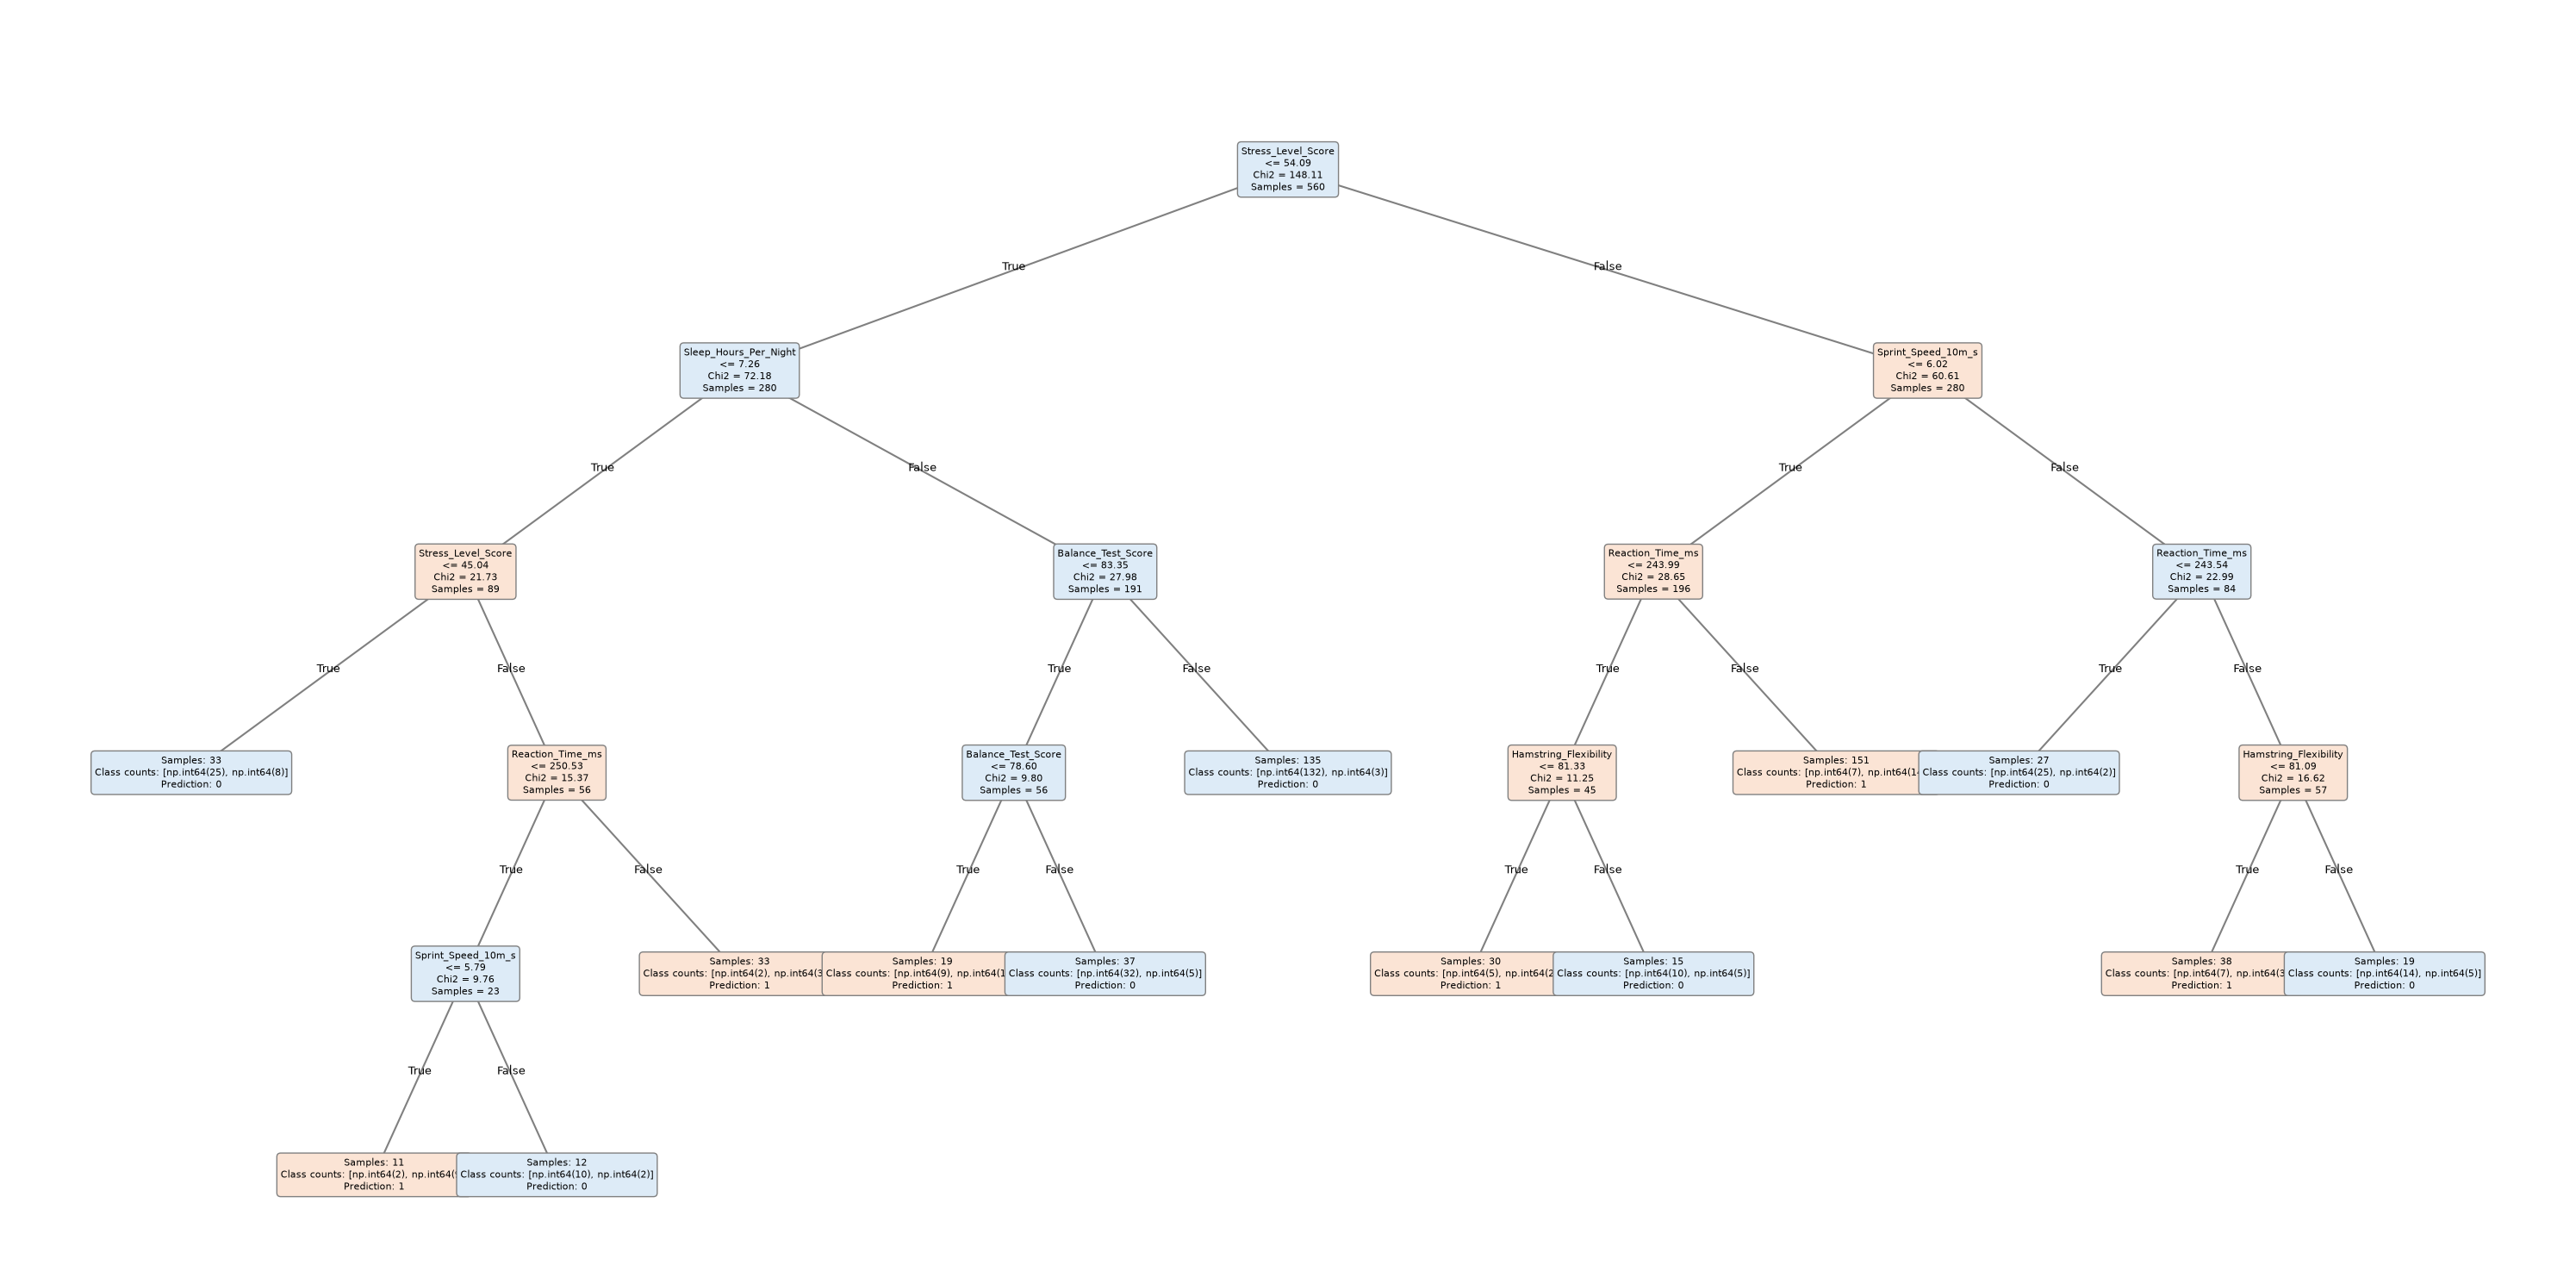

In [22]:
plot_chi2_tree(chi2_tree, max_display_depth=5)

In [23]:
# 結果表格

def extract_leaf_paths(model):

    leaf_records = []

    def traverse(node, path):

        # 判斷是否已經到達 Leaf Node
        if node["feature"] is None:

            n = node["n_samples"]
            count_0, count_1 = node["counts"]

            leaf_records.append({
                "Leaf ID": f"L{len(leaf_records) + 1}",
                "Depth": node["depth"],
                "Decision Path": " → ".join(path),
                "Samples": n,
                "Count 0": int(count_0),
                "Count 1": int(count_1),
                "0 (%)": round(count_0 / n * 100, 2),
                "1 (%)": round(count_1 / n * 100, 2),
                "Prediction": node["prediction"]
            })

            return

        # 取得目前節點的分裂資訊
        feature = node["feature"]
        threshold = node["threshold"]

        # 左子節點：符合 <= 的條件
        left_condition = f"{feature} <= {threshold:.3f}"

        traverse(
            node["left"],
            path + [left_condition]
        )

        # 右子節點：符合 > 的條件
        right_condition = f"{feature} > {threshold:.3f}"

        traverse(
            node["right"],
            path + [right_condition]
        )

    traverse(model.root_, [])

    return pd.DataFrame(leaf_records)

In [24]:
# 總leaf table

leaf_table = extract_leaf_paths(chi2_tree)

pd.set_option("display.max_colwidth", None)

display(leaf_table)

print("Leaf Nodes:", len(leaf_table))
print("Total Samples:", leaf_table["Samples"].sum())

,Leaf ID,Depth,Decision Path,Samples,Count 0,Count 1,0 (%),1 (%),Prediction
0,L1,3,Stress_Level_Score <= 54.092 → Sleep_Hours_Per_Night <= 7.264 → Stress_Level_Score <= 45.044,33,25,8,75.76,24.24,0
1,L2,5,Stress_Level_Score <= 54.092 → Sleep_Hours_Per_Night <= 7.264 → Stress_Level_Score > 45.044 → Reaction_Time_ms <= 250.526 → Sprint_Speed_10m_s <= 5.794,11,2,9,18.18,81.82,1
2,L3,5,Stress_Level_Score <= 54.092 → Sleep_Hours_Per_Night <= 7.264 → Stress_Level_Score > 45.044 → Reaction_Time_ms <= 250.526 → Sprint_Speed_10m_s > 5.794,12,10,2,83.33,16.67,0
3,L4,4,Stress_Level_Score <= 54.092 → Sleep_Hours_Per_Night <= 7.264 → Stress_Level_Score > 45.044 → Reaction_Time_ms > 250.526,33,2,31,6.06,93.94,1
4,L5,4,Stress_Level_Score <= 54.092 → Sleep_Hours_Per_Night > 7.264 → Balance_Test_Score <= 83.355 → Balance_Test_Score <= 78.595,19,9,10,47.37,52.63,1
5,L6,4,Stress_Level_Score <= 54.092 → Sleep_Hours_Per_Night > 7.264 → Balance_Test_Score <= 83.355 → Balance_Test_Score > 78.595,37,32,5,86.49,13.51,0
6,L7,3,Stress_Level_Score <= 54.092 → Sleep_Hours_Per_Night > 7.264 → Balance_Test_Score > 83.355,135,132,3,97.78,2.22,0
7,L8,4,Stress_Level_Score > 54.092 → Sprint_Speed_10m_s <= 6.017 → Reaction_Time_ms <= 243.995 → Hamstring_Flexibility <= 81.330,30,5,25,16.67,83.33,1
8,L9,4,Stress_Level_Score > 54.092 → Sprint_Speed_10m_s <= 6.017 → Reaction_Time_ms <= 243.995 → Hamstring_Flexibility > 81.330,15,10,5,66.67,33.33,0
9,L10,3,Stress_Level_Score > 54.092 → Sprint_Speed_10m_s <= 6.017 → Reaction_Time_ms > 243.995,151,7,144,4.64,95.36,1


Leaf Nodes: 13
Total Samples: 560


In [25]:
# 精簡版表格 w/預測值比例高低排列

leaf_risk_ranking = leaf_table.sort_values(
    by="1 (%)",
    ascending=False
).reset_index(drop=True)

display(
    leaf_risk_ranking[
        [
            "Leaf ID",
            "Decision Path",
            "Samples",
            "1 (%)",
            "Prediction"
        ]
    ]
)

,Leaf ID,Decision Path,Samples,1 (%),Prediction
0,L10,Stress_Level_Score > 54.092 → Sprint_Speed_10m_s <= 6.017 → Reaction_Time_ms > 243.995,151,95.36,1
1,L4,Stress_Level_Score <= 54.092 → Sleep_Hours_Per_Night <= 7.264 → Stress_Level_Score > 45.044 → Reaction_Time_ms > 250.526,33,93.94,1
2,L8,Stress_Level_Score > 54.092 → Sprint_Speed_10m_s <= 6.017 → Reaction_Time_ms <= 243.995 → Hamstring_Flexibility <= 81.330,30,83.33,1
3,L2,Stress_Level_Score <= 54.092 → Sleep_Hours_Per_Night <= 7.264 → Stress_Level_Score > 45.044 → Reaction_Time_ms <= 250.526 → Sprint_Speed_10m_s <= 5.794,11,81.82,1
4,L12,Stress_Level_Score > 54.092 → Sprint_Speed_10m_s > 6.017 → Reaction_Time_ms > 243.542 → Hamstring_Flexibility <= 81.087,38,81.58,1
5,L5,Stress_Level_Score <= 54.092 → Sleep_Hours_Per_Night > 7.264 → Balance_Test_Score <= 83.355 → Balance_Test_Score <= 78.595,19,52.63,1
6,L9,Stress_Level_Score > 54.092 → Sprint_Speed_10m_s <= 6.017 → Reaction_Time_ms <= 243.995 → Hamstring_Flexibility > 81.330,15,33.33,0
7,L13,Stress_Level_Score > 54.092 → Sprint_Speed_10m_s > 6.017 → Reaction_Time_ms > 243.542 → Hamstring_Flexibility > 81.087,19,26.32,0
8,L1,Stress_Level_Score <= 54.092 → Sleep_Hours_Per_Night <= 7.264 → Stress_Level_Score <= 45.044,33,24.24,0
9,L3,Stress_Level_Score <= 54.092 → Sleep_Hours_Per_Night <= 7.264 → Stress_Level_Score > 45.044 → Reaction_Time_ms <= 250.526 → Sprint_Speed_10m_s > 5.794,12,16.67,0


In [26]:
leaf_table["Correct Samples"] = leaf_table[
    ["Count 0", "Count 1"]
].max(axis=1)

accuracy_from_leaves = (
    leaf_table["Correct Samples"].sum()
    / leaf_table["Samples"].sum()
)

print(
    "Accuracy calculated from leaf nodes:",
    round(accuracy_from_leaves, 4)
)

print(
    "Original Training Accuracy:",
    round(chi2_train_acc, 4)
)

Accuracy calculated from leaf nodes: 0.8893
Original Training Accuracy: 0.8893


##### Pruning

In [27]:
from sklearn.metrics import accuracy_score

# 測試不同的alpha，觀察如何影響樹的複雜度
alpha_values = [0.01, 0.03, 0.05, 0.10, 0.15, 0.20]

chi2_candidates = {}
chi2_tuning_results = []

for alpha in alpha_values:

    model = ChiSquareTree(
        alpha=alpha,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        min_expected=5
    )

    model.fit(X_train_encoded, y_train)

    train_acc = accuracy_score(
        y_train,
        model.predict(X_train_encoded)
    )

    val_acc = accuracy_score(
        y_val,
        model.predict(X_val_encoded)
    )

    chi2_candidates[alpha] = model

    chi2_tuning_results.append({
        "Alpha": alpha,
        "Training Accuracy": train_acc,
        "Validation Accuracy": val_acc,
        "Tree Depth": model.get_depth(),
        "Leaf Nodes": model.get_n_leaves(),
        "Total Nodes": model.get_n_nodes()
    })

chi2_tuning_df = pd.DataFrame(chi2_tuning_results)

display(chi2_tuning_df.round(4))

,Alpha,Training Accuracy,Validation Accuracy,Tree Depth,Leaf Nodes,Total Nodes
0,0.01,0.8893,0.8417,5,13,25
1,0.03,0.8893,0.8417,5,13,25
2,0.05,0.8893,0.8417,5,13,25
3,0.10,0.8893,0.8417,5,13,25
4,0.15,0.8893,0.8417,5,13,25
5,0.20,0.8893,0.8417,5,13,25


In [28]:
# 優先選擇 Validation Accuracy 最高的模型；若 Accuracy 相同，就選擇葉節點較少的模型。

chi2_ranked = chi2_tuning_df.sort_values(
    by=[
        "Validation Accuracy",
        "Leaf Nodes",
        "Tree Depth",
        "Alpha"
    ],
    ascending=[False, True, True, True]
)

best_chi2_result = chi2_ranked.iloc[0]

best_chi2_alpha = float(best_chi2_result["Alpha"])
best_chi2_tree = chi2_candidates[best_chi2_alpha]

display(best_chi2_result.to_frame().T)

,Alpha,Training Accuracy,Validation Accuracy,Tree Depth,Leaf Nodes,Total Nodes
0,0.01,0.889286,0.841667,5.0,13.0,25.0


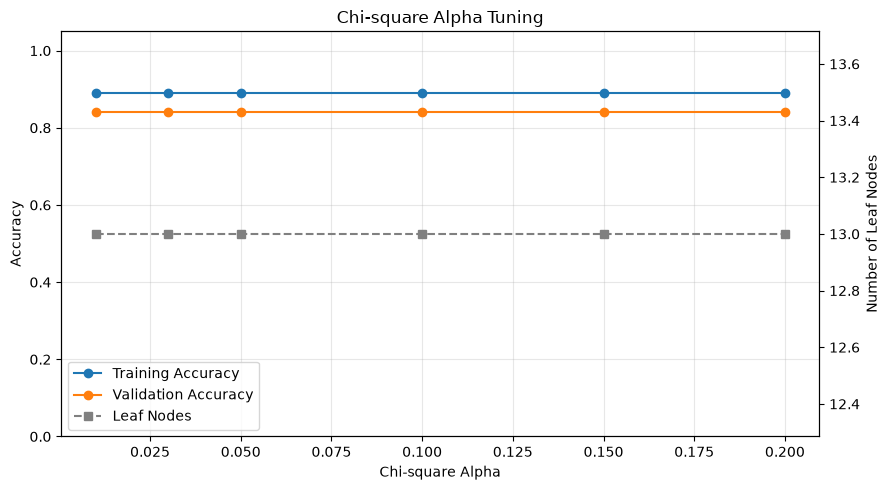

In [29]:

fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.plot(
    chi2_tuning_df["Alpha"],
    chi2_tuning_df["Training Accuracy"],
    marker="o",
    label="Training Accuracy"
)

ax1.plot(
    chi2_tuning_df["Alpha"],
    chi2_tuning_df["Validation Accuracy"],
    marker="o",
    label="Validation Accuracy"
)

ax1.set_xlabel("Chi-square Alpha")
ax1.set_ylabel("Accuracy")
ax1.set_ylim(0, 1.05)
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()

ax2.plot(
    chi2_tuning_df["Alpha"],
    chi2_tuning_df["Leaf Nodes"],
    marker="s",
    linestyle="--",
    color="gray",
    label="Leaf Nodes"
)

ax2.set_ylabel("Number of Leaf Nodes")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2)

plt.title("Chi-square Alpha Tuning")
plt.tight_layout()
plt.show()

In [30]:
# debug

def diagnose_chi2_leaves(model, X, y):

    X_array = X[model.feature_names_].to_numpy(dtype=float)
    y_array = y.to_numpy(dtype=int)

    records = []

    def traverse(node, indices, leaf_id_counter):

        if node["feature"] is None:

            X_node = X_array[indices]
            y_node = y_array[indices]

            counts = np.bincount(y_node, minlength=2)

            if np.count_nonzero(counts) == 1:
                reason = "Pure Node"
                best_p = np.nan

            elif len(y_node) < model.min_samples_split:
                reason = "Min Samples Split"
                best_p = np.nan

            elif (
                model.max_depth is not None
                and node["depth"] >= model.max_depth
            ):
                reason = "Max Depth"
                best_p = np.nan

            else:
                split = model._best_split(X_node, y_node)

                if split is None:
                    reason = "No Valid Split"
                    best_p = np.nan
                else:
                    best_p = split["p_value"]

                    if best_p >= model.alpha:
                        reason = "Alpha Threshold"
                    else:
                        reason = "Other"

            leaf_id_counter[0] += 1

            records.append({
                "Leaf ID": f"L{leaf_id_counter[0]}",
                "Depth": node["depth"],
                "Samples": len(y_node),
                "Count 0": counts[0],
                "Count 1": counts[1],
                "Stop Reason": reason,
                "Best Available p-value": best_p
            })

            return

        feature_idx = node["feature_idx"]
        threshold = node["threshold"]

        left_mask = (
            X_array[indices, feature_idx] <= threshold
        )

        traverse(
            node["left"],
            indices[left_mask],
            leaf_id_counter
        )

        traverse(
            node["right"],
            indices[~left_mask],
            leaf_id_counter
        )

    traverse(
        model.root_,
        np.arange(len(y_array)),
        [0]
    )

    return pd.DataFrame(records)

In [31]:
# debug

leaf_diagnosis = diagnose_chi2_leaves(
    chi2_tree,
    X_train_encoded,
    y_train
)

display(leaf_diagnosis)

print("\nStopping Reason Summary:")
display(leaf_diagnosis["Stop Reason"].value_counts())

,Leaf ID,Depth,Samples,Count 0,Count 1,Stop Reason,Best Available p-value
0,L1,3,33,25,8,No Valid Split,NaN
1,L2,5,11,2,9,No Valid Split,NaN
2,L3,5,12,10,2,No Valid Split,NaN
3,L4,4,33,2,31,No Valid Split,NaN
4,L5,4,19,9,10,No Valid Split,NaN
5,L6,4,37,32,5,No Valid Split,NaN
6,L7,3,135,132,3,No Valid Split,NaN
7,L8,4,30,5,25,No Valid Split,NaN
8,L9,4,15,10,5,No Valid Split,NaN
9,L10,3,151,7,144,No Valid Split,NaN



Stopping Reason Summary:


Stop Reason
No Valid Split    13
Name: count, dtype: int64

### Entropy & Gini Tree

In [32]:
# 建立未經剪枝的初始模型

gini_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

entropy_tree = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

gini_tree.fit(X_train_encoded, y_train)
entropy_tree.fit(X_train_encoded, y_train)

print("Gini 和 Entropy Growing 完成！")

Gini 和 Entropy Growing 完成！


In [33]:
# 比較三棵初始樹

models = {
    "Chi-square": chi2_tree,
    "Entropy": entropy_tree,
    "Gini": gini_tree
}

growing_results = []

for name, model in models.items():

    train_acc = accuracy_score(
        y_train,
        model.predict(X_train_encoded)
    )

    val_acc = accuracy_score(
        y_val,
        model.predict(X_val_encoded)
    )

    growing_results.append({
        "Criterion": name,
        "Training Accuracy": train_acc,
        "Validation Accuracy": val_acc,
        "Tree Depth": model.get_depth(),
        "Leaf Nodes": model.get_n_leaves()
    })

growing_results = pd.DataFrame(growing_results)

display(growing_results.round(4))

,Criterion,Training Accuracy,Validation Accuracy,Tree Depth,Leaf Nodes
0,Chi-square,0.8893,0.8417,5,13
1,Entropy,1.0000,0.8083,8,48
2,Gini,1.0000,0.8500,8,53


第一，Entropy 和 Gini 都能完全分類 Training Data。 但它們在 Validation Data 上分別只有 80.83% 和 85.00%，顯示兩棵樹可能有過度擬合（Overfitting）的現象。

第二，Chi-square 的樹明顯比較簡單。 它只有 13 個葉節點，而 Entropy、Gini 分別有 48 和 53 個。主要原因之一是 Chi-square 使用了額外的顯著性停止條件 \(\alpha=0.1\)，因此不能直接認定 Chi-square 分裂準則天生就會產生較小的樹。

第三，目前 Gini 的 Validation Accuracy 最高，但只比 Chi-square 高出 0.83 個百分點，也就是 120 筆 Validation Data 中多預測正確 1 筆。 這個差距很小，不適合現在就判斷 Gini 比較好。

#### Pruning

In [34]:
# Entropy、Gini 各自產生一系列剪枝程度不同的樹
# 用 Validation Accuracy 評估

cart_models = {
    "Entropy": entropy_tree,
    "Gini": gini_tree
}

pruning_results = []
pruned_candidates = {}

for criterion_name, original_model in cart_models.items():

    # 取得 Cost-Complexity Pruning Path
    path = original_model.cost_complexity_pruning_path(
        X_train_encoded,
        y_train
    )

    alphas = np.unique(path.ccp_alphas)

    pruned_candidates[criterion_name] = []

    for alpha in alphas:

        model = DecisionTreeClassifier(
            criterion=criterion_name.lower(),
            ccp_alpha=float(alpha),
            random_state=42
        )

        # 只使用 Training Data 重新訓練
        model.fit(X_train_encoded, y_train)

        train_acc = accuracy_score(
            y_train,
            model.predict(X_train_encoded)
        )

        val_acc = accuracy_score(
            y_val,
            model.predict(X_val_encoded)
        )

        pruning_results.append({
            "Criterion": criterion_name,
            "ccp_alpha": alpha,
            "Training Accuracy": train_acc,
            "Validation Accuracy": val_acc,
            "Tree Depth": model.get_depth(),
            "Leaf Nodes": model.get_n_leaves()
        })

        pruned_candidates[criterion_name].append(model)

pruning_df = pd.DataFrame(pruning_results)

print("Pruning candidates generated!")

display(
    pruning_df.groupby("Criterion").size()
)

Pruning candidates generated!


Criterion
Entropy    37
Gini       41
dtype: int64

In [35]:
best_cart_summary = (
    pruning_df
    .sort_values(
        by=[
            "Criterion",
            "Validation Accuracy",
            "Leaf Nodes",
            "Tree Depth"
        ],
        ascending=[True, False, True, True]
    )
    .groupby("Criterion", as_index=False)
    .first()
)

display(best_cart_summary.round(4))

,Criterion,ccp_alpha,Training Accuracy,Validation Accuracy,Tree Depth,Leaf Nodes
0,Entropy,0.0261,0.8661,0.8250,4,9
1,Gini,0.0033,0.9661,0.8583,7,30


In [36]:
# 保存最佳模型

best_cart_models = {}

for criterion_name in ["Entropy", "Gini"]:

    selected = best_cart_summary[
        best_cart_summary["Criterion"] == criterion_name
    ].iloc[0]

    # 使用候選模型中對應的 ccp_alpha
    candidates = pruning_df[
        pruning_df["Criterion"] == criterion_name
    ].reset_index(drop=True)

    best_idx = candidates.index[
        np.isclose(
            candidates["ccp_alpha"],
            selected["ccp_alpha"],
            rtol=1e-10,
            atol=1e-12
        )
    ]

    # 若有極接近的 alpha，依已選結果優先比對葉節點數
    best_idx = [
        i for i in best_idx
        if candidates.loc[i, "Leaf Nodes"]
        == selected["Leaf Nodes"]
    ][0]

    best_cart_models[criterion_name] = (
        pruned_candidates[criterion_name][best_idx]
    )

print("Best Entropy and Gini models saved!")

Best Entropy and Gini models saved!


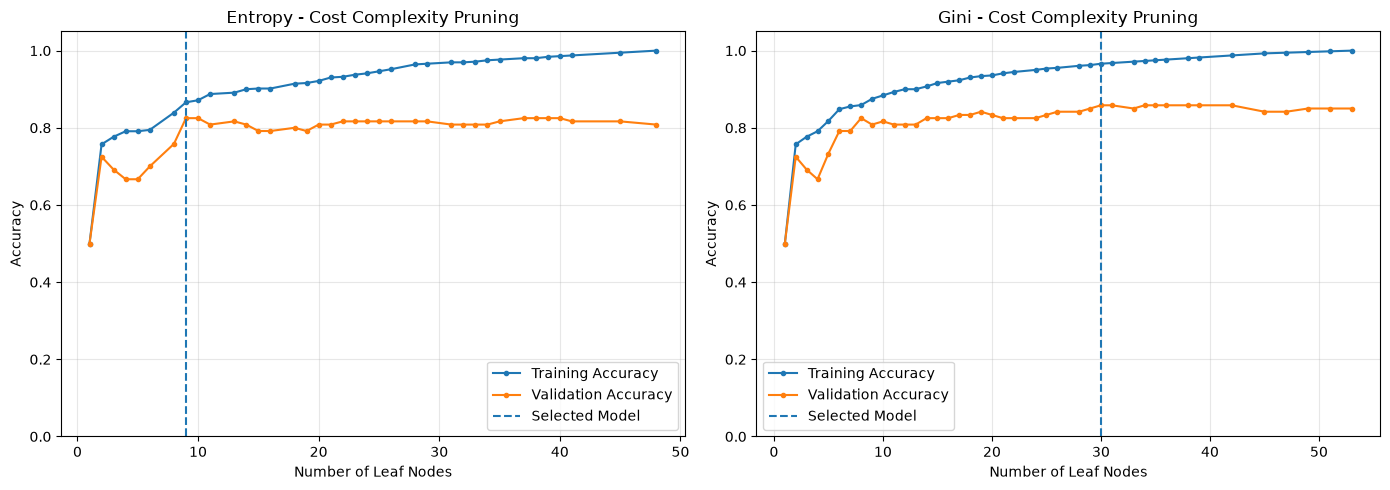

In [37]:
# 比較pruning前後的validation accuracy

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, name in zip(axes, ["Entropy", "Gini"]):

    subset = pruning_df[
        pruning_df["Criterion"] == name
    ].sort_values("Leaf Nodes")

    ax.plot(
        subset["Leaf Nodes"],
        subset["Training Accuracy"],
        marker="o",
        markersize=3,
        label="Training Accuracy"
    )

    ax.plot(
        subset["Leaf Nodes"],
        subset["Validation Accuracy"],
        marker="o",
        markersize=3,
        label="Validation Accuracy"
    )

    best = best_cart_summary[
        best_cart_summary["Criterion"] == name
    ].iloc[0]

    ax.axvline(
        best["Leaf Nodes"],
        linestyle="--",
        label="Selected Model"
    )

    ax.set_title(f"{name} - Cost Complexity Pruning")
    ax.set_xlabel("Number of Leaf Nodes")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

## Testing

In [45]:
# 固定三種最終模型
final_models = {
    "Chi-square": best_chi2_tree,
    "Entropy": best_cart_models["Entropy"],
    "Gini": best_cart_models["Gini"]
}

for name, model in final_models.items():
    print(
        name,
        "| Depth:", model.get_depth(),
        "| Leaves:", model.get_n_leaves()
    )

Chi-square | Depth: 5 | Leaves: 13
Entropy | Depth: 4 | Leaves: 9
Gini | Depth: 7 | Leaves: 30


模型是否能夠正確辨識出受傷的球員？

我們將 Injury_Next_Season=1 定義為 Positive Class。

四個指標為：
指標	公式	解釋
Accuracy	\((TP+TN)/N\)	整體分類正確率
Precision	\(TP/(TP+FP)\)	預測會受傷的人中，有多少真的受傷
Recall	\(TP/(TP+FN)\)	真正受傷的人中，有多少被成功找出
F1-score	\(2PR/(P+R)\)	綜合考量 Precision 與 Recall

In [46]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

test_results = []
test_predictions = {}

for name, model in final_models.items():

    # 使用 Testing Data 預測
    y_pred = model.predict(X_test_encoded)

    test_predictions[name] = y_pred

    test_results.append({
        "Criterion": name,
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Test Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "Test F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "Tree Depth": model.get_depth(),
        "Leaf Nodes": model.get_n_leaves()
    })

test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))

,Criterion,Test Accuracy,Test Precision,Test Recall,Test F1,Tree Depth,Leaf Nodes
0,Chi-square,0.7583,0.7719,0.7333,0.7521,5,13
1,Entropy,0.7333,0.6795,0.8833,0.7681,4,9
2,Gini,0.8250,0.8095,0.8500,0.8293,7,30


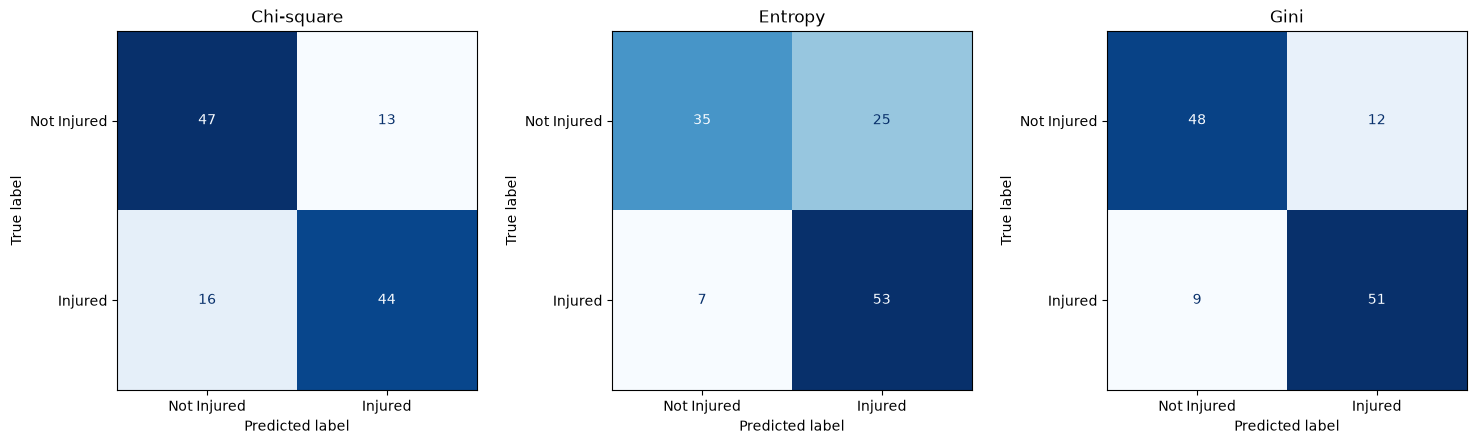

In [47]:
# 畫出confusion matrix

import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.5)
)

for ax, (name, y_pred) in zip(
    axes, test_predictions.items()
):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not Injured", "Injured"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

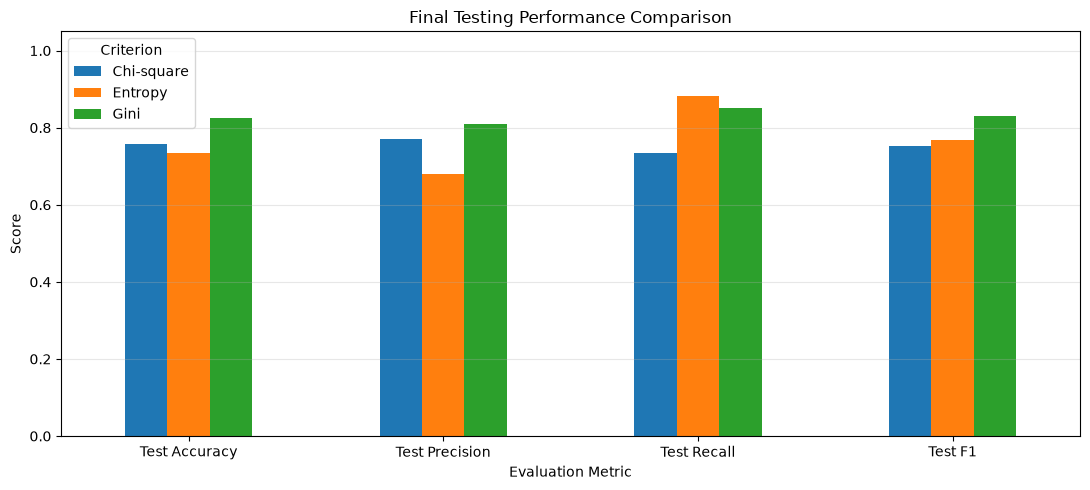

In [48]:
metrics = [
    "Test Accuracy",
    "Test Precision",
    "Test Recall",
    "Test F1"
]

ax = (
    test_results_df
    .set_index("Criterion")[metrics]
    .T
    .plot(
        kind="bar",
        figsize=(11, 5),
        rot=0
    )
)

ax.set_title("Final Testing Performance Comparison")
ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### AUC/ROC

In [49]:
# 若要觀察chi_square樹的預測分數，需要轉成對testing data的預測機率。
# 讓每筆 Testing Data 找到所屬的葉節點，再以該葉節點的受傷比例作為預測分數。

def chi2_predict_proba(model, X):

    X_array = X[model.feature_names_].to_numpy(dtype=float)
    probabilities = []

    for row in X_array:

        node = model.root_

        # 沿著決策樹走到 Leaf Node
        while node["feature"] is not None:

            feature_idx = node["feature_idx"]
            threshold = node["threshold"]

            if row[feature_idx] <= threshold:
                node = node["left"]
            else:
                node = node["right"]

        # 使用 Leaf Node 的受傷比例
        count_0, count_1 = node["counts"]
        probability = count_1 / (count_0 + count_1)

        probabilities.append(probability)

    return np.array(probabilities)

In [50]:
from sklearn.metrics import roc_curve, roc_auc_score

# 計算三種模型的 ROC-AUC
# 三種模型預測受傷的分數
roc_scores = {
    "Chi-square": chi2_predict_proba(
        final_models["Chi-square"], X_test_encoded
    ),

    "Entropy": final_models["Entropy"].predict_proba(
        X_test_encoded
    )[:, 1],

    "Gini": final_models["Gini"].predict_proba(
        X_test_encoded
    )[:, 1]
}

auc_results = []

for name, scores in roc_scores.items():

    auc_value = roc_auc_score(y_test, scores)

    auc_results.append({
        "Criterion": name,
        "ROC-AUC": auc_value
    })

auc_df = pd.DataFrame(auc_results)

display(auc_df.round(4))

,Criterion,ROC-AUC
0,Chi-square,0.8383
1,Entropy,0.8028
2,Gini,0.8357


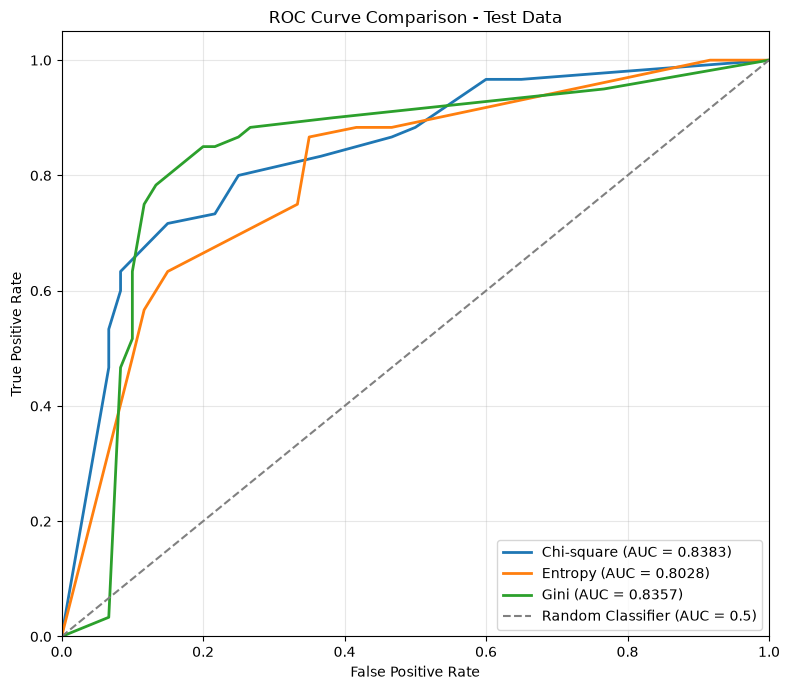

In [51]:
# plot

plt.figure(figsize=(8, 7))

for name, scores in roc_scores.items():

    fpr, tpr, thresholds = roc_curve(
        y_test, scores
    )

    auc_value = roc_auc_score(
        y_test, scores
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_value:.4f})"
    )

# 隨機分類基準線
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier (AUC = 0.5)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison - Test Data")

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()